# Identificación automática de tonos de color: de la foto de una prenda al catálogo de colorantes textiles
**Proyecto Visión por Computador — CRISP-DM etapas 1 y 2: comprensión del negocio y de los datos**

Dataset: *Fashion Product Images* (Param Aggarwal, Kaggle), versión *small* publicada en Hugging Face (`ashraq/fashion-product-images-small`).

Este notebook sigue el **checklist de exploración de datos** del curso (12 secciones) y termina con la propuesta de estrategia de modelado.

## 0. Comprensión del negocio

**Contexto.** Una empresa fabricante de **colorantes para el sector textil** recibe en su área comercial requerimientos de tintorerías, confeccionistas y marcas. Una de las formas más comunes en que llegan es una **foto de una prenda**: «quiero este color». Hoy el asesor comercial:

1. interpreta a ojo el tono de la foto («un azul petróleo»), y cada asesor lo nombra distinto;
2. con ese nombre recorre el **catálogo de colorantes** buscando la referencia más cercana, lo que depende de su experiencia;
3. entrega un punto de partida al laboratorio. Si ese punto está lejos, se repiten **pruebas de tinturado** y la respuesta al cliente se demora.

**Propuesta.** Usar un dataset público de fotos de prendas con su tono etiquetado (*Fashion Product Images*, 46 tonos) para entrenar un modelo que **reconozca el color de una prenda en una foto**. Con cada requerimiento nuevo:

> foto del cliente → segmentar la prenda → modelo: tono (top-3) y color CIELAB → comparar por ΔE2000 contra el catálogo de colorantes → sugerir al comercial las referencias más cercanas

El laboratorio sigue validando con pruebas físicas: el modelo entrega un **mejor punto de partida**, no reemplaza la igualación de color. Para el despliegue, la empresa debe aportar su catálogo con las coordenadas Lab de cada referencia.

**Objetivo de negocio.** Apoyar al área comercial a responder más rápido, con menos reprocesos y de forma consistente los requerimientos que llegan como foto.

**Objetivo de visión por computador.** Clasificación de imágenes **multiclase** (46 tonos finos) con una salida jerárquica de **13 grupos de color básico**, más la estimación del color Lab de la prenda segmentada.

**Criterios de éxito (propuestos).**

| Nivel | Métrica | Meta inicial |
|---|---|---|
| Grupo básico (13) | Accuracy / F1-macro | ≥ 90 % / ≥ 0,80 |
| Tono fino (46) | Top-1 / Top-3 accuracy | ≥ 70 % / ≥ 90 % |
| Tono fino | Error perceptual medio ΔE2000 entre el tono predicho y el real | menor que el de la línea base clásica |
| Comercial | % de sugerencias top-3 que el asesor acepta | ≥ 80 % |
| Comercial | Tiempo de respuesta al requerimiento | menor que el actual (medirlo primero) |

**Preguntas que debe responder el EDA.** ¿Cuántos tonos hay y qué tan desbalanceados están? ¿Qué tan separables son en un espacio de color perceptual (CIELAB)? ¿Qué tan confiables son las etiquetas? ¿Qué sesgos (tipo de producto, fondo, persona) pueden engañar al modelo?

In [1]:
import sys, warnings
from pathlib import Path
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

from core import config
from core.datos import cargar_dataset, decodificar, abrir
from core.color import (describir_dataset, mascara_primer_plano, mascara_piel,
                        lab_a_rgb, matriz_delta_e)

config.RUTA_FIGURAS.mkdir(exist_ok=True)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "savefig.bbox": "tight", "savefig.dpi": 150})
rng = np.random.default_rng(config.SEMILLA)

def guardar(nombre):
    plt.savefig(config.RUTA_FIGURAS / f"{nombre}.png")

ok, df, mensaje = cargar_dataset()
print(mensaje)
assert ok, mensaje

44,072 registros leídos de 2 archivos


## 1. Estructura del dataset
* **Formato:** 2 archivos parquet con la metadata y la imagen JPEG embebida (sin carpetas por clase).
* **Etiqueta objetivo:** `baseColour`. Las demás columnas (género, categoría, tipo de artículo, temporada, uso, nombre comercial) sirven para analizar sesgos y para validar las etiquetas.

In [2]:
print(f"Registros: {len(df):,}  |  Columnas: {df.shape[1]}")
print(f"Tonos (clases): {df['baseColour'].nunique()}  |  Grupos básicos: {df['grupo_color'].nunique()}")
print(f"Ids duplicados: {df['id'].duplicated().sum()}")
display(df.drop(columns="imagen_bytes").head())
display(df.drop(columns="imagen_bytes").describe(include="object").T)

Registros: 44,072  |  Columnas: 12
Tonos (clases): 46  |  Grupos básicos: 13
Ids duplicados: 0


,id,gender,masterCategory,subCategory,articleType,baseColour,season,year,usage,productDisplayName,grupo_color
0,15970,Men,Apparel,Topwear,Shirts,Navy Blue,Fall,2011.0,Casual,Turtle Check Men Navy Blue Shirt,Azul
1,39386,Men,Apparel,Bottomwear,Jeans,Blue,Summer,2012.0,Casual,Peter England Men Party Blue Jeans,Azul
2,59263,Women,Accessories,Watches,Watches,Silver,Winter,2016.0,Casual,Titan Women Silver Watch,Metálico
3,21379,Men,Apparel,Bottomwear,Track Pants,Black,Fall,2011.0,Casual,Manchester United Men Solid Black Track Pants,Negro
4,53759,Men,Apparel,Topwear,Tshirts,Grey,Summer,2012.0,Casual,Puma Men Grey T-shirt,Gris


,count,unique,top,freq
gender,44072,5,Men,22104
masterCategory,44072,7,Apparel,21361
subCategory,44072,45,Topwear,15383
articleType,44072,141,Tshirts,7065
baseColour,44072,46,Black,9699
season,44072,4,Summer,21438
usage,44072,8,Casual,34392
productDisplayName,44072,30801,Lucera Women Silver Earrings,82
grupo_color,44072,13,Negro,9699


In [3]:
# Definición de clases: 46 tonos finos agrupados en 13 colores básicos (catálogo en core/config.py)
tabla_grupos = (df.groupby(["grupo_color", "baseColour"]).size().rename("imagenes")
                  .reset_index().sort_values(["grupo_color", "imagenes"], ascending=[True, False]))
tabla_grupos.groupby("grupo_color").agg(tonos=("baseColour", lambda s: ", ".join(s)),
                                         imagenes=("imagenes", "sum")).sort_values("imagenes", ascending=False)

,tonos,imagenes
grupo_color,,
Negro,Black,9699
Azul,"Blue, Navy Blue, Teal, Turquoise Blue",6878
Blanco,"White, Cream, Off White",6062
Café,"Brown, Beige, Skin, Khaki, Tan, Coffee Brown, ...",4676
Gris,"Grey, Charcoal, Grey Melange",3109
Rojo,"Red, Maroon, Burgundy",3053
Verde,"Green, Olive, Sea Green, Fluorescent Green, Li...",2544
Metálico,"Silver, Gold, Steel, Bronze, Copper, Metallic",2238
Rosado,"Pink, Peach, Magenta, Rose",2158


## 2. Estadísticas básicas
Para cada imagen se calculan descriptores (`core/color.py`): tamaño, modo de color, hashes (MD5 exacto y *dHash* perceptual), **máscara de primer plano** (ΔE2000 contra el color del borde y apertura morfológica), color mediano del producto en CIELAB, croma, nitidez (varianza del Laplaciano), brillo, contraste y fracción de píxeles tipo piel. El resultado se guarda en caché.

In [4]:
%%time
desc = describir_dataset(df)
d = df.drop(columns="imagen_bytes").set_index("id").join(desc)
print(f"Imágenes con error de lectura: {d['error'].notna().sum()}")

Imágenes con error de lectura: 0
CPU times: total: 250 ms
Wall time: 162 ms


In [5]:
print("Tamaños (ancho x alto):")
print((d["ancho"].astype(str) + "x" + d["alto"].astype(str)).value_counts().to_string())
print("\nRelación de aspecto (alto/ancho):", (d["alto"] / d["ancho"]).round(3).value_counts().to_dict())
print("\nModo de color:", d["modo"].value_counts().to_dict())

Tamaños (ancho x alto):
60x80    44049
53x80       10
60x60        5
54x80        2
60x79        2
60x77        2
60x75        1
60x76        1

Relación de aspecto (alto/ancho): {1.333: 44049, 1.509: 10, 1.0: 5, 1.481: 2, 1.317: 2, 1.283: 2, 1.25: 1, 1.267: 1}

Modo de color: {'RGB': 43642, 'L': 430}


In [6]:
dup_exactos = d[d.duplicated("md5", keep=False)]
dup_percep = d[d.duplicated("dhash", keep=False)]
conflicto_md5 = dup_exactos.groupby("md5")["baseColour"].nunique()
conflicto = dup_percep.groupby("dhash")["baseColour"].nunique()
n_conf_md5 = int((conflicto_md5 > 1).sum())
print(f"Duplicados exactos (MD5): {len(dup_exactos):,} imágenes en {dup_exactos['md5'].nunique():,} grupos")
print(f"  -> misma imagen con etiquetas de tono distintas: {n_conf_md5} grupos "
      f"({dup_exactos[dup_exactos['md5'].isin(conflicto_md5[conflicto_md5 > 1].index)].shape[0]} imágenes)")
print(f"Casi-duplicados (dHash 16x16 idéntico): {len(dup_percep):,} imágenes en {dup_percep['dhash'].nunique():,} grupos")
print(f"  -> con etiquetas de tono distintas: {(conflicto > 1).sum():,} grupos")

Duplicados exactos (MD5): 1,429 imágenes en 651 grupos
  -> misma imagen con etiquetas de tono distintas: 52 grupos (105 imágenes)
Casi-duplicados (dHash 16x16 idéntico): 2,046 imágenes en 843 grupos
  -> con etiquetas de tono distintas: 199 grupos


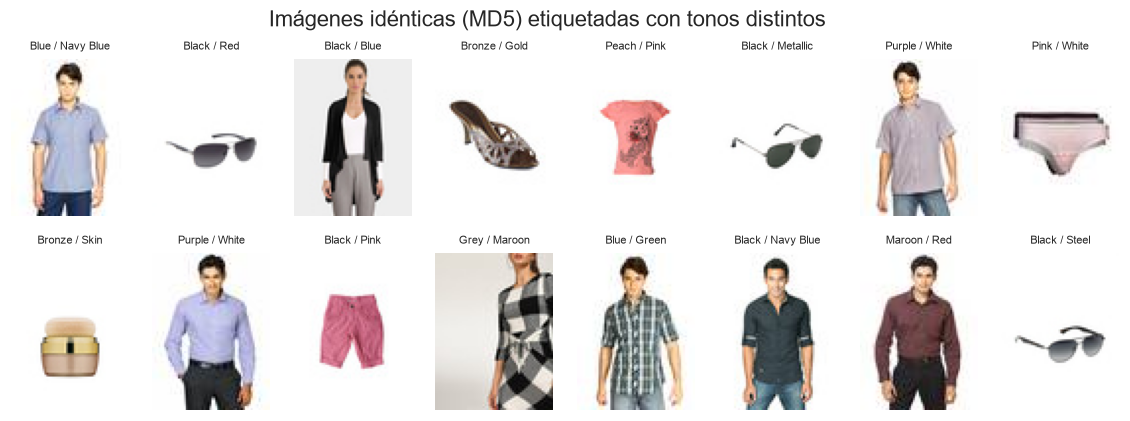

In [7]:
# La MISMA imagen (MD5 idéntico) publicada con dos tonos distintos = ruido de etiqueta seguro
grupos_ej = conflicto_md5[conflicto_md5 > 1].index[:16]
bytes_por_id = df.set_index("id")["imagen_bytes"]
fig, axes = plt.subplots(2, 8, figsize=(13, 4.2))
for ax, h in zip(axes.flat, grupos_ej):
    ids = d.index[d["md5"] == h]
    ax.imshow(decodificar(bytes_por_id[ids[0]])); ax.axis("off")
    ax.set_title(" / ".join(sorted(d.loc[ids, "baseColour"].unique())), fontsize=7)
for ax in axes.flat[len(grupos_ej):]:
    ax.axis("off")
plt.suptitle("Imágenes idénticas (MD5) etiquetadas con tonos distintos")
guardar("02_duplicados_conflicto")
plt.show()

## 3. Visualización

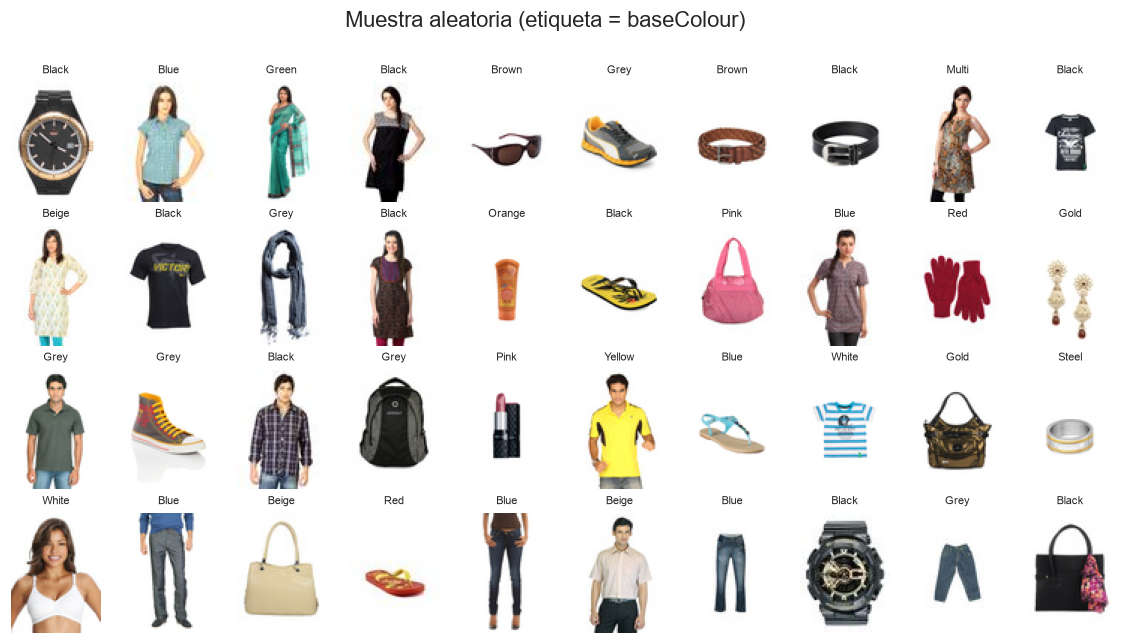

In [8]:
muestra = df.sample(40, random_state=config.SEMILLA)
fig, axes = plt.subplots(4, 10, figsize=(13, 6.5))
for ax, (_, r) in zip(axes.flat, muestra.iterrows()):
    ax.imshow(decodificar(r.imagen_bytes)); ax.set_title(r.baseColour, fontsize=7); ax.axis("off")
plt.suptitle("Muestra aleatoria (etiqueta = baseColour)")
guardar("03_muestra_aleatoria")
plt.show()

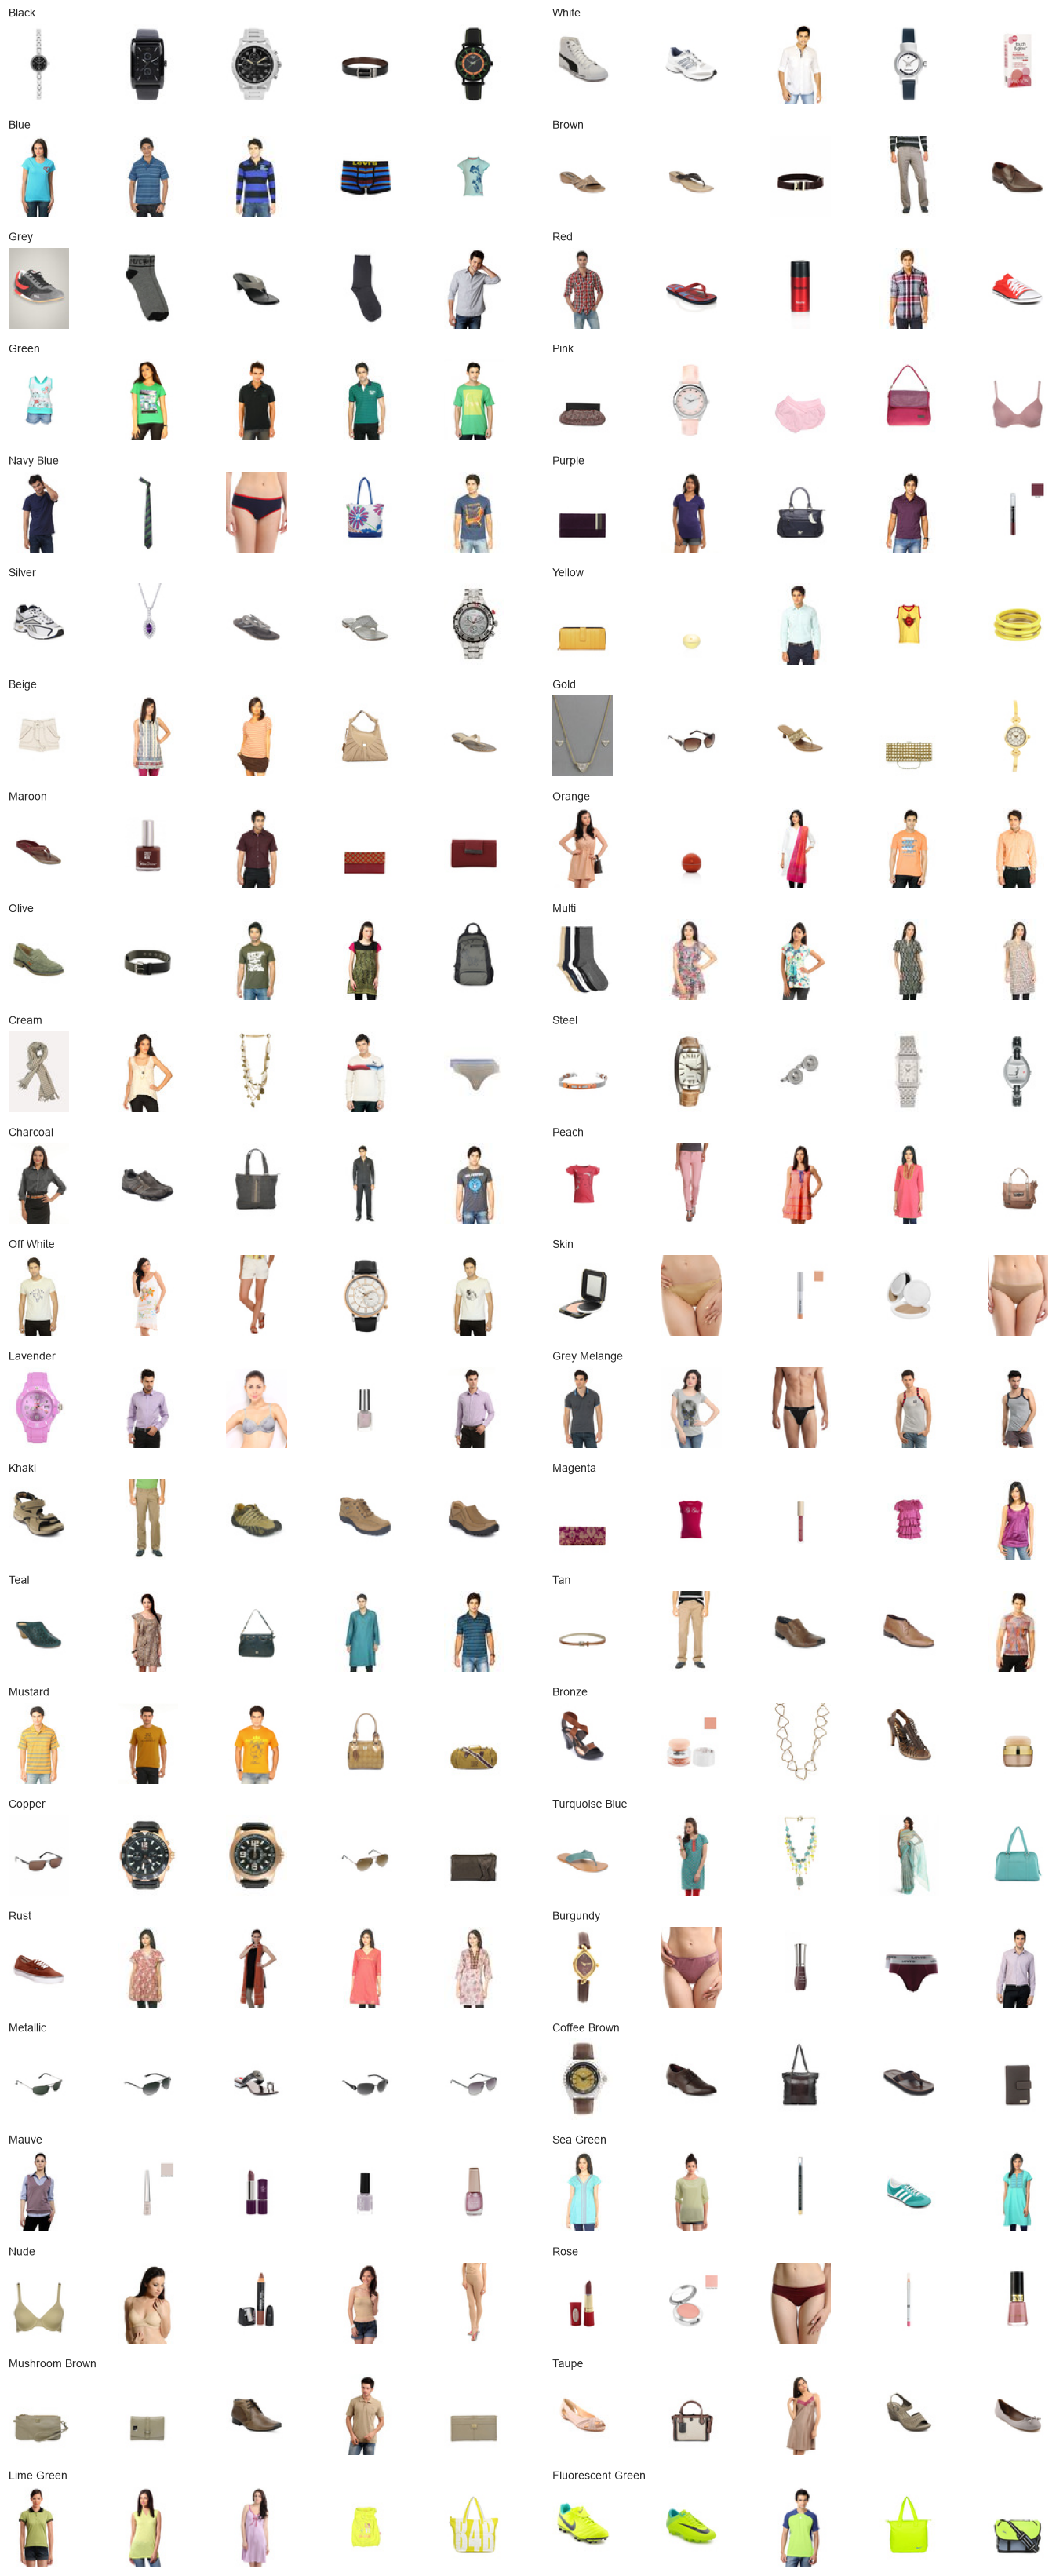

In [9]:
# Ejemplos por tono (5 por clase), ordenados por frecuencia
orden_tonos = d["baseColour"].value_counts().index.tolist()
n_ej = 5
fig, axes = plt.subplots(len(orden_tonos) // 2, 2 * n_ej, figsize=(13, 30))
for k, tono in enumerate(orden_tonos):
    fila, col0 = k // 2, (k % 2) * n_ej
    ids = d.index[d["baseColour"] == tono].to_numpy()
    for j, i in enumerate(rng.choice(ids, size=min(n_ej, len(ids)), replace=False)):
        axes[fila, col0 + j].imshow(decodificar(bytes_por_id[i]))
    axes[fila, col0].set_title(tono, fontsize=9, loc="left")
for ax in axes.flat:
    ax.axis("off")
plt.tight_layout()
guardar("03_ejemplos_por_tono")
plt.show()

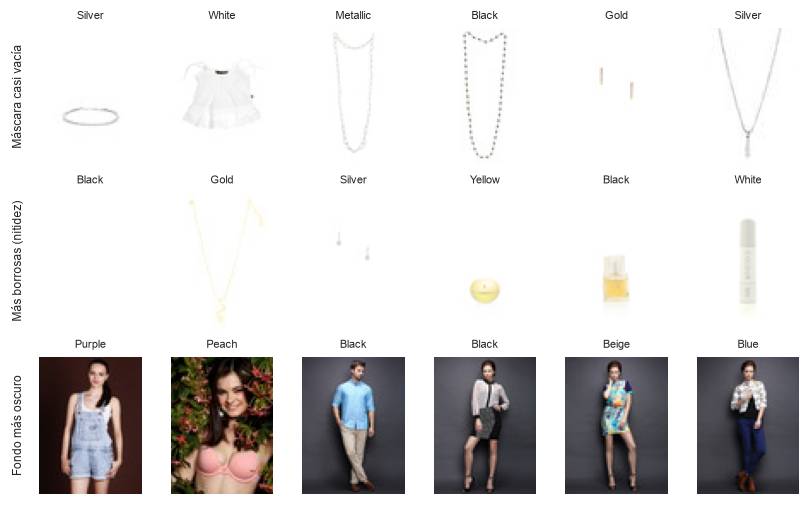

In [10]:
# Casos límite: máscara casi vacía (producto blanco sobre fondo blanco), más borrosas y fondo no blanco
casos = {
    "Máscara casi vacía": d.nsmallest(6, "frac_primer_plano").index,
    "Más borrosas (nitidez)": d.nsmallest(6, "nitidez").index,
    "Fondo más oscuro": d.nsmallest(6, "L_fondo").index,
}
fig, axes = plt.subplots(3, 6, figsize=(9, 5.5))
for fila, (titulo, ids) in zip(axes, casos.items()):
    for ax, i in zip(fila, ids):
        ax.imshow(decodificar(bytes_por_id[i])); ax.set_title(d.at[i, "baseColour"], fontsize=7); ax.axis("off")
    fila[0].text(-0.15, 0.5, titulo, transform=fila[0].transAxes, rotation=90, va="center", ha="right", fontsize=8)
guardar("03_casos_limite")
plt.show()

## 4. Distribución de clases

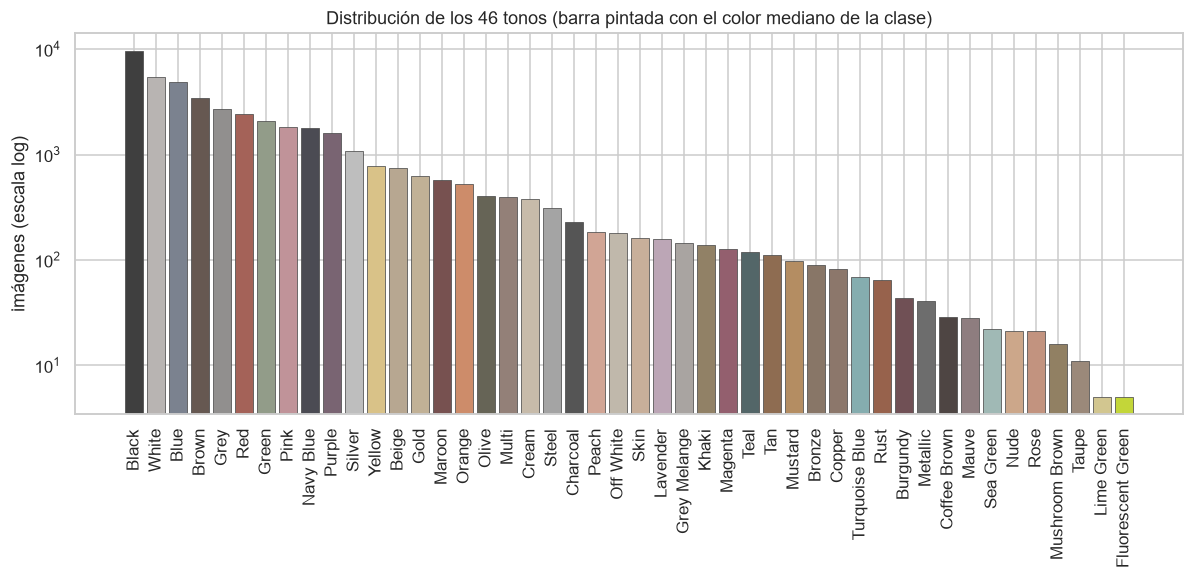

Razón de desbalance (mayor/menor): 1,940x  (Black 9,699 vs Lime Green 5)
Las 5 clases más grandes concentran 60% de los datos
Clases con < 100 imágenes: 16  |  con < 30: 9


In [11]:
# Color representativo de cada tono = mediana Lab de los productos de esa clase
centroides = d.groupby("baseColour")[["L", "a", "b"]].median()
color_tono = {t: lab_a_rgb(centroides.loc[t].values)[0] for t in centroides.index}

conteo = d["baseColour"].value_counts()
fig, ax = plt.subplots(figsize=(13, 4.5))
ax.bar(conteo.index, conteo.values, color=[color_tono[t] for t in conteo.index], edgecolor="0.3", linewidth=0.5)
ax.set_yscale("log"); ax.set_ylabel("imágenes (escala log)")
ax.tick_params(axis="x", rotation=90)
ax.set_title("Distribución de los 46 tonos (barra pintada con el color mediano de la clase)")
guardar("04_distribucion_tonos")
plt.show()

print(f"Razón de desbalance (mayor/menor): {conteo.max() / conteo.min():,.0f}x  ({conteo.idxmax()} {conteo.max():,} vs {conteo.idxmin()} {conteo.min():,})")
print(f"Las 5 clases más grandes concentran {conteo.head(5).sum() / conteo.sum():.0%} de los datos")
print(f"Clases con < 100 imágenes: {(conteo < 100).sum()}  |  con < 30: {(conteo < 30).sum()}")

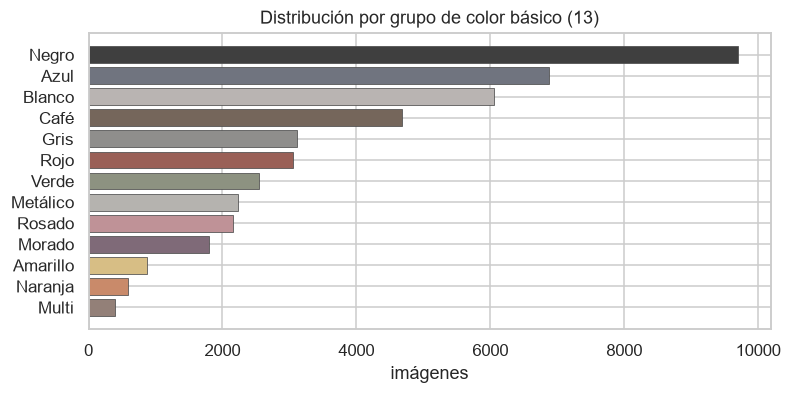

In [12]:
grupo = d["grupo_color"].value_counts()
fig, ax = plt.subplots(figsize=(8, 3.5))
cent_g = d.groupby("grupo_color")[["L", "a", "b"]].median()
ax.barh(grupo.index[::-1], grupo.values[::-1],
        color=[lab_a_rgb(cent_g.loc[g].values)[0] for g in grupo.index[::-1]], edgecolor="0.3", linewidth=0.5)
ax.set_xlabel("imágenes"); ax.set_title("Distribución por grupo de color básico (13)")
guardar("04_distribucion_grupos")
plt.show()

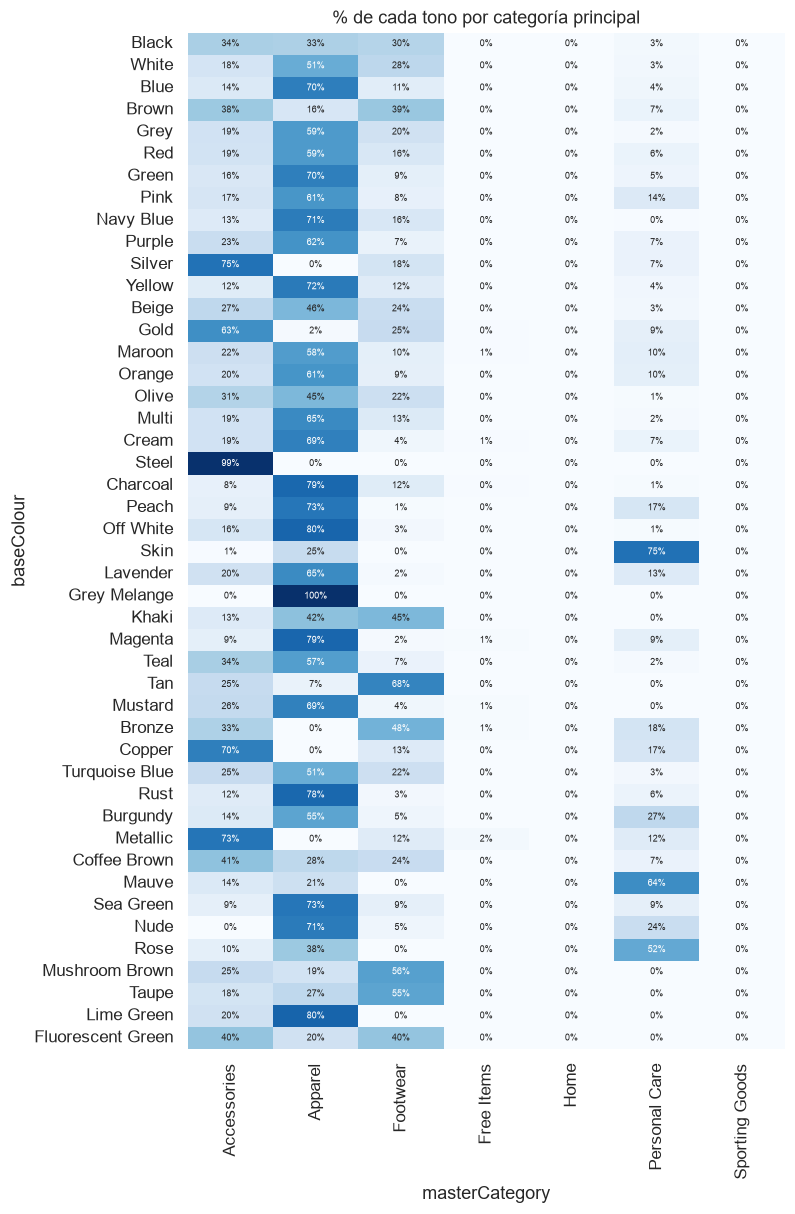

In [13]:
# Subatributos: ¿el tono depende del tipo de producto? (riesgo de "atajo": aprender la categoría en vez del color)
ct = pd.crosstab(d["baseColour"], d["masterCategory"], normalize="index").loc[orden_tonos]
fig, ax = plt.subplots(figsize=(7, 12))
sns.heatmap(ct, cmap="Blues", annot=True, fmt=".0%", annot_kws={"size": 6}, cbar=False, ax=ax)
ax.set_title("% de cada tono por categoría principal")
guardar("04_tono_vs_categoria")
plt.show()

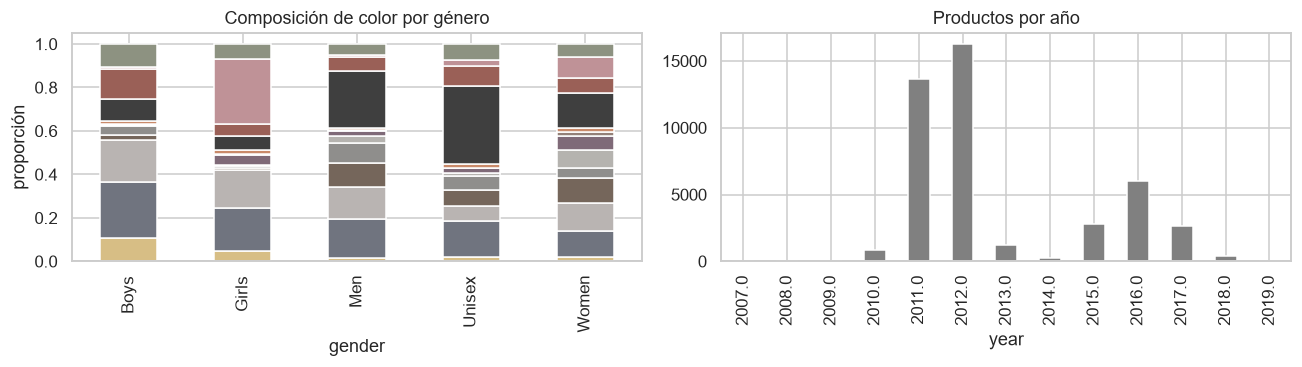

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
pd.crosstab(d["grupo_color"], d["gender"], normalize="columns").T.plot.bar(stacked=True, ax=axes[0], legend=False,
    color=[lab_a_rgb(cent_g.loc[g].values)[0] for g in sorted(d["grupo_color"].unique())])
axes[0].set_title("Composición de color por género"); axes[0].set_ylabel("proporción")
d["year"].value_counts().sort_index().plot.bar(ax=axes[1], color="0.5")
axes[1].set_title("Productos por año")
plt.tight_layout(); guardar("04_genero_anio"); plt.show()

## 5. Calidad de los datos

In [15]:
print(f"Imágenes corruptas o ilegibles: {d['error'].notna().sum()}")
gris = d[d["modo"] == "L"]
print(f"Imágenes en escala de grises (modo L): {len(gris)}")
print("  tonos que declaran:", gris["baseColour"].value_counts().head(10).to_dict())
umbral_borrosa = d["nitidez"].quantile(0.01)
print(f"Imágenes borrosas (1 % con menor nitidez, var. Laplaciano < {umbral_borrosa:.0f}): {(d['nitidez'] < umbral_borrosa).sum()}")
print(f"Máscara de producto insuficiente (< {config.FRACCION_MINIMA_PRIMER_PLANO:.0%} de la imagen): {d['fallback_mascara'].sum()}")

Imágenes corruptas o ilegibles: 0
Imágenes en escala de grises (modo L): 430
  tonos que declaran: {'Black': 277, 'White': 75, 'Silver': 29, 'Steel': 26, 'Grey': 13, 'Charcoal': 3, 'Grey Melange': 2, 'Purple': 1, 'Navy Blue': 1, 'Pink': 1}
Imágenes borrosas (1 % con menor nitidez, var. Laplaciano < 190): 441
Máscara de producto insuficiente (< 3% de la imagen): 405


**Consistencia de etiquetas.** El nombre comercial (`productDisplayName`) suele incluir el color ("Turtle Check Men *Navy Blue* Shirt"). Se compara la etiqueta `baseColour` con el tono que aparece en el nombre; es una auditoría barata de la calidad de la etiqueta.

In [16]:
import re
tonos_ordenados = sorted(d["baseColour"].unique(), key=len, reverse=True)  # "Navy Blue" antes que "Blue"
patron = re.compile(r"\b(" + "|".join(re.escape(t) for t in tonos_ordenados) + r")\b", re.IGNORECASE)
mapa_min = {t.lower(): t for t in tonos_ordenados}

def tono_en_nombre(nombre):
    m = patron.search(str(nombre))
    return mapa_min[m.group(1).lower()] if m else None

d["tono_nombre"] = d["productDisplayName"].map(tono_en_nombre)
con_tono = d[d["tono_nombre"].notna()]
acuerdo_fino = (con_tono["tono_nombre"] == con_tono["baseColour"]).mean()
acuerdo_grupo = (con_tono["tono_nombre"].map(config.TONO_A_GRUPO) == con_tono["grupo_color"]).mean()
print(f"Nombres que mencionan un tono: {len(con_tono):,} ({len(con_tono) / len(d):.0%})")
print(f"Acuerdo etiqueta vs nombre  -> tono fino: {acuerdo_fino:.1%}  |  grupo básico: {acuerdo_grupo:.1%}")

desacuerdos = con_tono[con_tono["tono_nombre"] != con_tono["baseColour"]]
print("\nPares de desacuerdo más frecuentes (etiqueta -> nombre):")
print(desacuerdos.groupby(["baseColour", "tono_nombre"]).size().sort_values(ascending=False).head(12).to_string())

Nombres que mencionan un tono: 40,475 (92%)
Acuerdo etiqueta vs nombre  -> tono fino: 93.5%  |  grupo básico: 94.9%

Pares de desacuerdo más frecuentes (etiqueta -> nombre):
baseColour    tono_nombre
Black         Red            191
Brown         Red            156
White         Red             47
              Blue            46
Navy Blue     Blue            45
White         Black           45
Blue          Navy Blue       42
Grey Melange  Grey            40
Black         White           36
Pink          Red             34
Black         Silver          33
Green         Olive           33


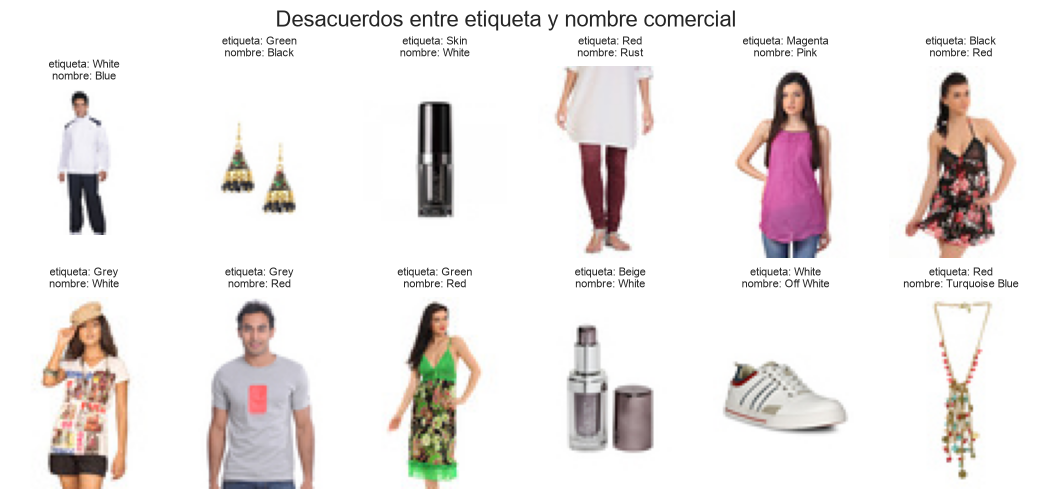

In [17]:
ej = desacuerdos.sample(12, random_state=config.SEMILLA)
fig, axes = plt.subplots(2, 6, figsize=(12, 5))
for ax, (i, r) in zip(axes.flat, ej.iterrows()):
    ax.imshow(decodificar(bytes_por_id[i])); ax.axis("off")
    ax.set_title(f"etiqueta: {r.baseColour}\nnombre: {r.tono_nombre}", fontsize=7)
plt.suptitle("Desacuerdos entre etiqueta y nombre comercial")
guardar("05_desacuerdos_etiqueta")
plt.show()

## 6. Características de las imágenes

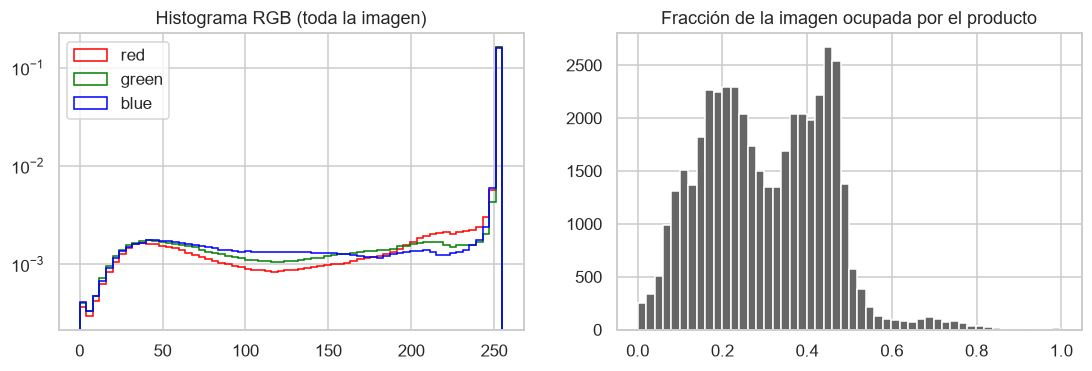

Píxeles casi blancos (>240 en los 3 canales): 67%


In [18]:
# Histogramas de intensidad por canal (muestra de 3.000 imágenes)
ids_m = rng.choice(d.index.to_numpy(), 3000, replace=False)
pix = np.concatenate([decodificar(bytes_por_id[i]).reshape(-1, 3) for i in ids_m])
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
for c, col in enumerate(["red", "green", "blue"]):
    axes[0].hist(pix[:, c], bins=64, histtype="step", color=col, density=True, label=col)
axes[0].set_yscale("log"); axes[0].set_title("Histograma RGB (toda la imagen)"); axes[0].legend()
axes[1].hist(d["frac_primer_plano"], bins=50, color="0.4")
axes[1].set_title("Fracción de la imagen ocupada por el producto")
guardar("06_histogramas"); plt.show()
print(f"Píxeles casi blancos (>240 en los 3 canales): {(pix > 240).all(axis=1).mean():.0%}")

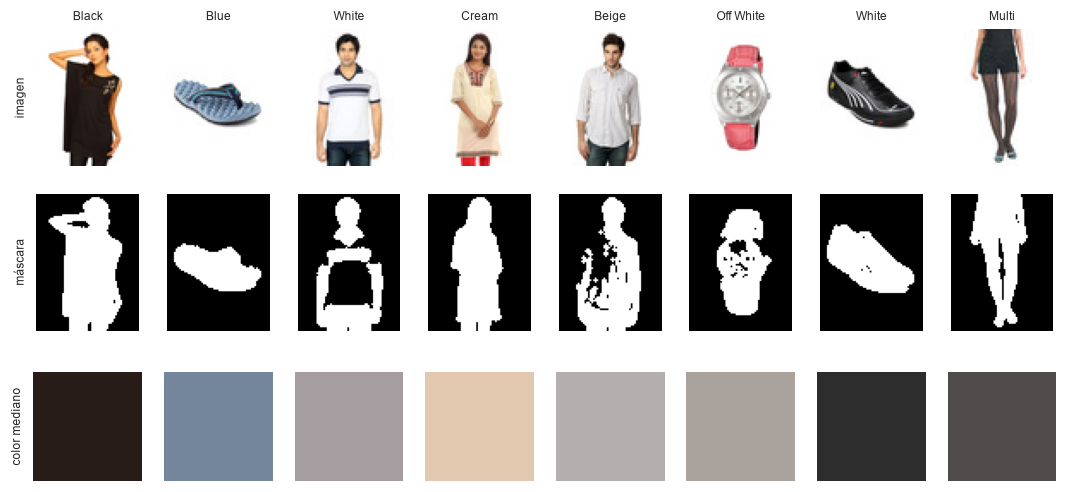

In [19]:
# Ejemplos de máscara de primer plano y color mediano extraído
ej = d.sample(8, random_state=3).index
fig, axes = plt.subplots(3, 8, figsize=(12, 5.5))
for k, i in enumerate(ej):
    rgb = decodificar(bytes_por_id[i]); m, _, _ = mascara_primer_plano(rgb)
    axes[0, k].imshow(rgb); axes[0, k].set_title(d.at[i, "baseColour"], fontsize=8)
    axes[1, k].imshow(m, cmap="gray")
    axes[2, k].imshow(np.ones((10, 10, 3)) * lab_a_rgb(d.loc[i, ["L", "a", "b"]].values.astype(float))[0])
for ax in axes.flat: ax.axis("off")
for fila, t in zip(axes[:, 0], ["imagen", "máscara", "color mediano"]):
    fila.text(-0.1, 0.5, t, transform=fila.transAxes, rotation=90, va="center", ha="right", fontsize=8)
guardar("06_mascaras"); plt.show()

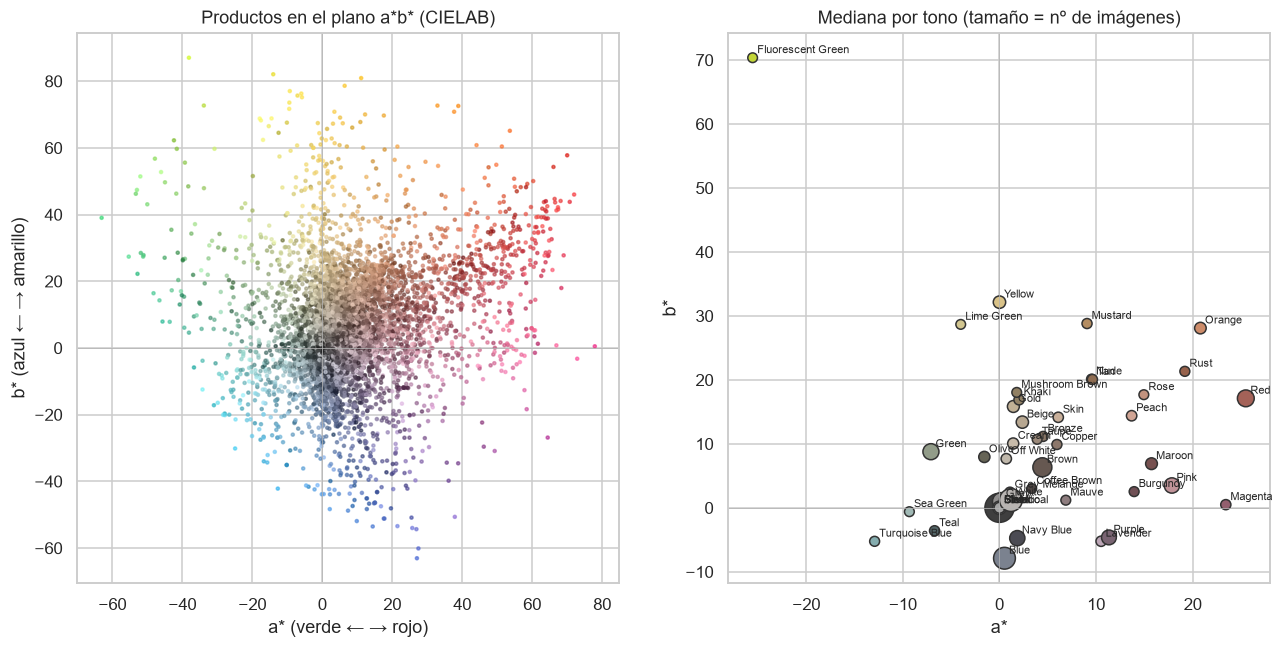

In [20]:
# Espacio de color perceptual: cada punto es el color mediano de un producto, pintado con ese mismo color
m = d[d["grupo_color"] != "Multi"].sample(12000, random_state=config.SEMILLA)
fig, axes = plt.subplots(1, 2, figsize=(14, 6.5))
axes[0].scatter(m["a"], m["b"], c=lab_a_rgb(m[["L", "a", "b"]].values), s=4, alpha=0.6)
axes[0].set(xlabel="a* (verde ← → rojo)", ylabel="b* (azul ← → amarillo)", title="Productos en el plano a*b* (CIELAB)")
cent_plot = centroides.drop("Multi")
axes[1].scatter(cent_plot["a"], cent_plot["b"], c=[color_tono[t] for t in cent_plot.index],
                s=40 + conteo[cent_plot.index].values / 30, edgecolor="0.2")
for t, r in cent_plot.iterrows():
    axes[1].annotate(t, (r["a"], r["b"]), fontsize=7, xytext=(3, 3), textcoords="offset points")
axes[1].set(xlabel="a*", ylabel="b*", title="Mediana por tono (tamaño = nº de imágenes)")
for ax in axes: ax.axhline(0, c="0.7", lw=0.5); ax.axvline(0, c="0.7", lw=0.5)
guardar("06_plano_ab"); plt.show()

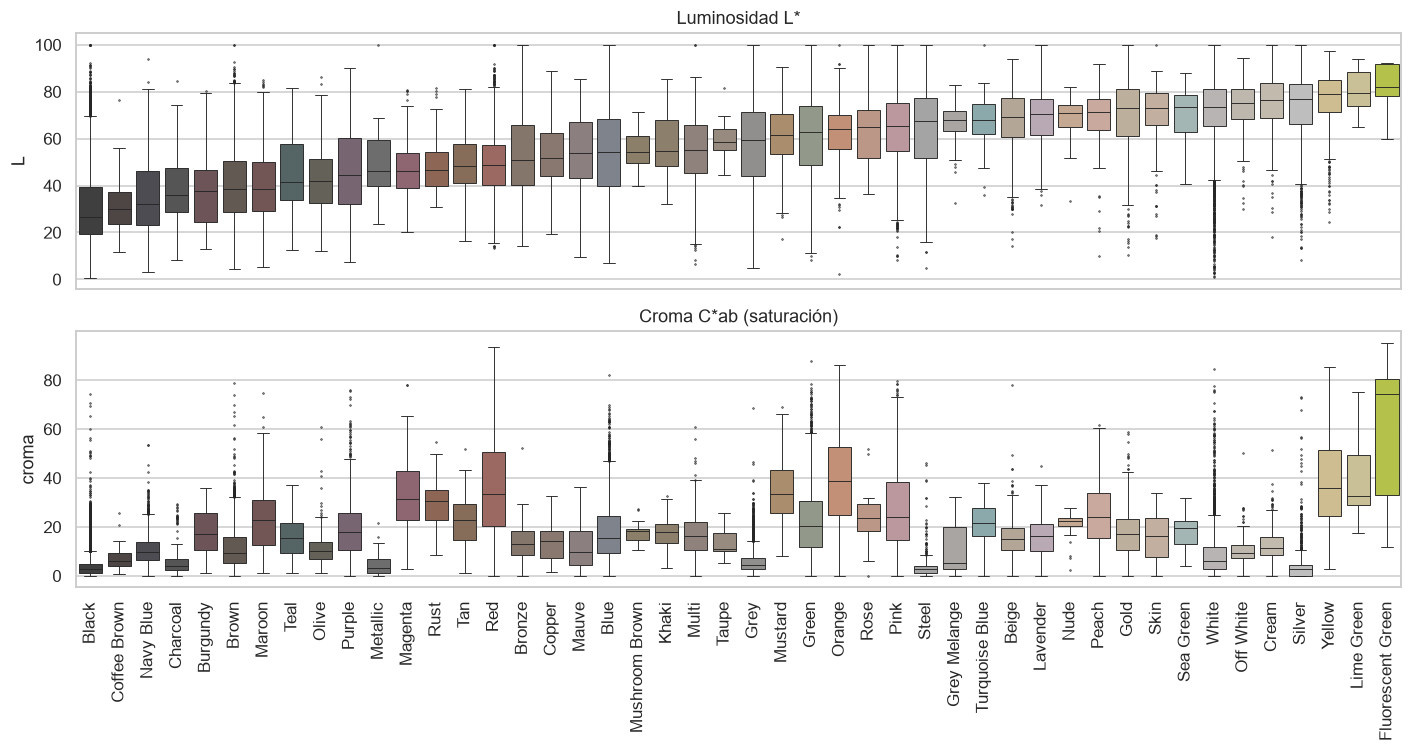

In [21]:
# Luminosidad L* y croma por tono: los tonos acromáticos se separan solo por L*
orden_L = centroides["L"].sort_values().index
fig, axes = plt.subplots(2, 1, figsize=(13, 7), sharex=True)
for ax, var, tit in [(axes[0], "L", "Luminosidad L*"), (axes[1], "croma", "Croma C*ab (saturación)")]:
    sns.boxplot(data=d, x="baseColour", y=var, order=orden_L, palette=[color_tono[t] for t in orden_L],
                fliersize=0.5, linewidth=0.6, ax=ax)
    ax.set_title(tit); ax.set_xlabel("")
axes[1].tick_params(axis="x", rotation=90)
plt.tight_layout(); guardar("06_L_croma_por_tono"); plt.show()

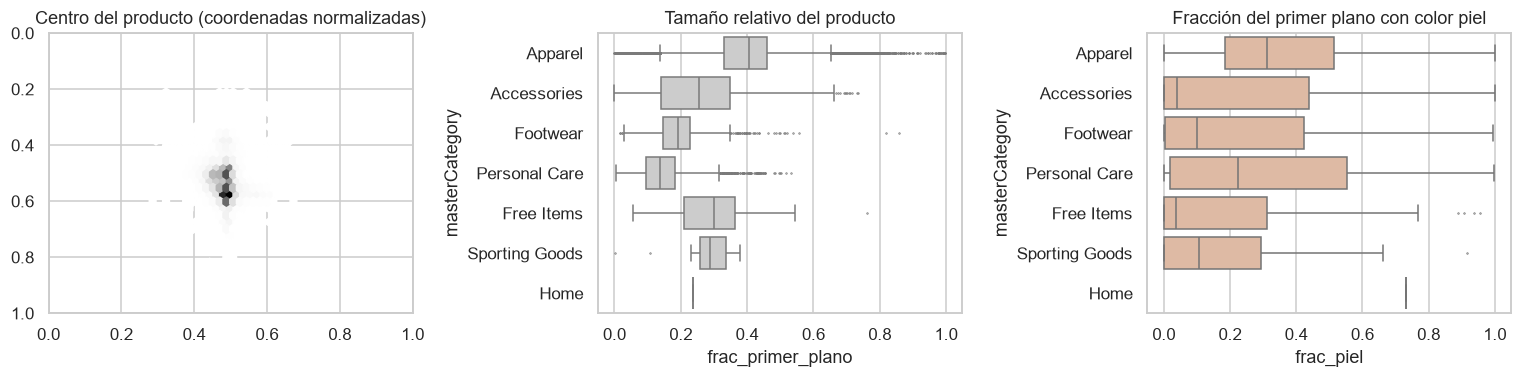

Imágenes con >10 % de píxeles tipo piel en el primer plano: 66%
  por categoría: {'Accessories': '43%', 'Apparel': '86%', 'Footwear': '50%', 'Free Items': '44%', 'Home': '100%', 'Personal Care': '63%', 'Sporting Goods': '52%'}
  (heurística YCrCb: también marca productos beige/café/naranja, así que sobreestima la presencia de personas)


In [22]:
# Variabilidad de tamaño y posición del objeto + presencia de personas (piel)
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
axes[0].hexbin(d["centro_x"], d["centro_y"], gridsize=30, cmap="Greys", mincnt=1)
axes[0].set(title="Centro del producto (coordenadas normalizadas)", xlim=(0, 1), ylim=(1, 0))
sns.boxplot(data=d, y="masterCategory", x="frac_primer_plano", ax=axes[1], color="0.8", fliersize=0.5)
axes[1].set_title("Tamaño relativo del producto")
sns.boxplot(data=d, y="masterCategory", x="frac_piel", ax=axes[2], color="#e8b89a", fliersize=0.5)
axes[2].set_title("Fracción del primer plano con color piel")
plt.tight_layout(); guardar("06_tamano_posicion_piel"); plt.show()
con_persona = d["frac_piel"] > 0.10
print(f"Imágenes con >10 % de píxeles tipo piel en el primer plano: {con_persona.mean():.0%}")
print("  por categoría:", d.groupby("masterCategory")["frac_piel"].apply(lambda s: f"{(s > 0.10).mean():.0%}").to_dict())
print("  (heurística YCrCb: también marca productos beige/café/naranja, así que sobreestima la presencia de personas)")

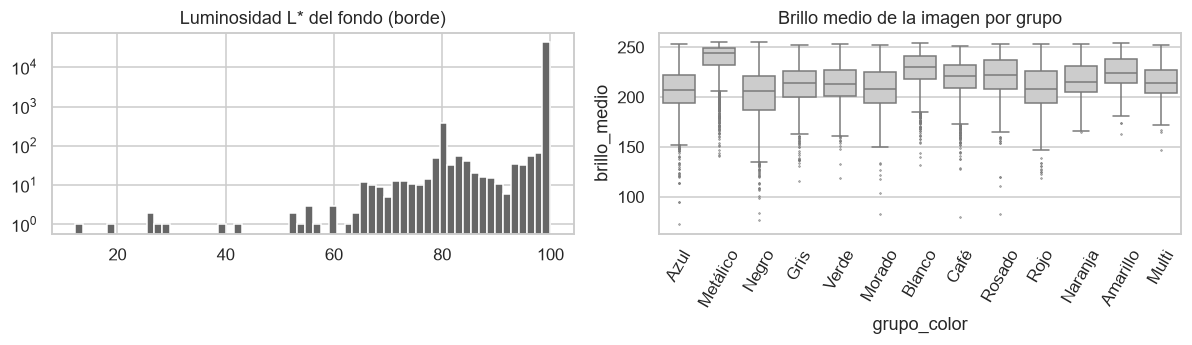

Fondo claro (L* > 95): 98.2% de las imágenes


In [23]:
# Sesgos de fondo e iluminación
fig, axes = plt.subplots(1, 2, figsize=(11, 3.3))
axes[0].hist(d["L_fondo"], bins=60, color="0.4"); axes[0].set_yscale("log")
axes[0].set_title("Luminosidad L* del fondo (borde)")
sns.boxplot(data=d, x="grupo_color", y="brillo_medio", ax=axes[1], color="0.8", fliersize=0.5)
axes[1].tick_params(axis="x", rotation=60); axes[1].set_title("Brillo medio de la imagen por grupo")
plt.tight_layout(); guardar("06_fondo_brillo"); plt.show()
print(f"Fondo claro (L* > 95): {(d['L_fondo'] > 95).mean():.1%} de las imágenes")

## 7. Necesidades de preprocesamiento

In [24]:
media = d[["r_medio", "g_medio", "b_medio"]].mean().values
std = np.sqrt(d[["r_std", "g_std", "b_std"]].pow(2).mean().values)
tabla = pd.DataFrame({"dataset_media": media, "dataset_std": std,
                      "imagenet_media": [0.485, 0.456, 0.406], "imagenet_std": [0.229, 0.224, 0.225]},
                     index=["R", "G", "B"]).round(3)
display(tabla)

,dataset_media,dataset_std,imagenet_media,imagenet_std
R,0.854,0.254,0.485,0.229
G,0.836,0.266,0.456,0.224
B,0.830,0.269,0.406,0.225


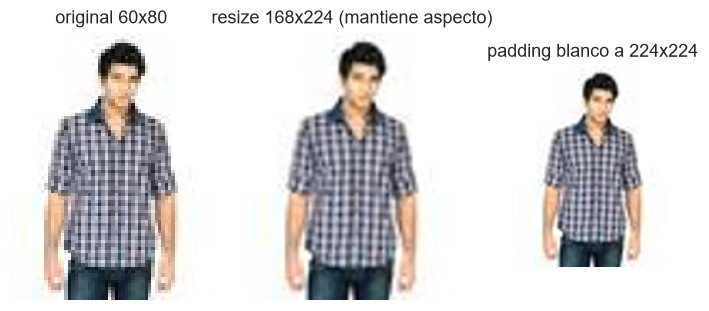

In [25]:
# Efecto del resize: la versión small es 60x80; los modelos preentrenados esperan 224x224
i = d.index[d["baseColour"] == "Navy Blue"][0]
img = abrir(bytes_por_id[i]).convert("RGB")
fig, axes = plt.subplots(1, 3, figsize=(8, 3.5))
axes[0].imshow(img); axes[0].set_title("original 60x80")
axes[1].imshow(img.resize((168, 224), Image.BICUBIC)); axes[1].set_title("resize 168x224 (mantiene aspecto)")
lienzo = Image.new("RGB", (224, 224), (255, 255, 255)); lienzo.paste(img.resize((168, 224), Image.BICUBIC), (28, 0))
axes[2].imshow(lienzo); axes[2].set_title("padding blanco a 224x224")
for ax in axes: ax.axis("off")
guardar("07_resize"); plt.show()

## 8. Data augmentation
En este problema **el color es la etiqueta**: las transformaciones fotométricas usuales (*ColorJitter* de tono y saturación) cambian la clase. Abajo se compara el ΔE2000 entre el color mediano original y el transformado. Un ΔE > 10 equivale a otro tono para un observador humano.

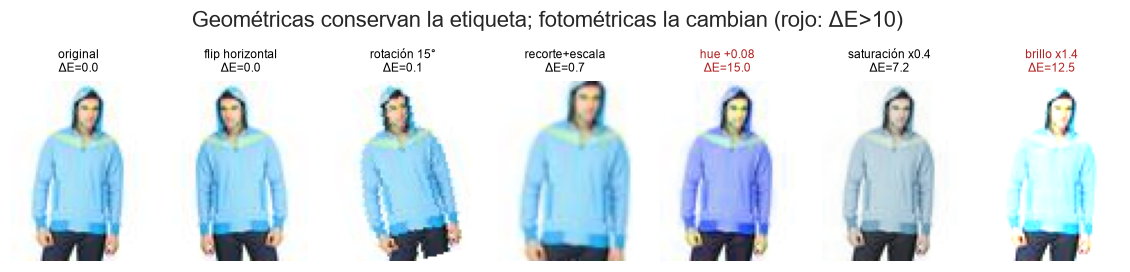

In [26]:
from torchvision.transforms import v2 as T
from skimage import color as skcolor

def color_mediano(pil):
    rgb = np.asarray(pil.convert("RGB")); m, lab, _ = mascara_primer_plano(rgb)
    return np.median(lab[m] if m.mean() > 0.03 else lab.reshape(-1, 3), axis=0)

i = d.index[(d["baseColour"] == "Blue") & (d["masterCategory"] == "Apparel")][3]
img = abrir(bytes_por_id[i]).convert("RGB")
transformaciones = {
    "original": lambda x: x,
    "flip horizontal": T.RandomHorizontalFlip(p=1),
    "rotación 15°": T.RandomRotation((15, 15), fill=255),
    "recorte+escala": T.RandomResizedCrop((80, 60), scale=(0.7, 0.7), ratio=(0.75, 0.75)),
    "hue +0.08": lambda x: T.functional.adjust_hue(x, 0.08),
    "saturación x0.4": lambda x: T.functional.adjust_saturation(x, 0.4),
    "brillo x1.4": lambda x: T.functional.adjust_brightness(x, 1.4),
}
lab0 = color_mediano(img)
fig, axes = plt.subplots(1, len(transformaciones), figsize=(13, 3))
for ax, (nombre, t) in zip(axes, transformaciones.items()):
    out = t(img); de = skcolor.deltaE_ciede2000(lab0, color_mediano(out))
    ax.imshow(out); ax.axis("off")
    ax.set_title(f"{nombre}\nΔE={de:.1f}", fontsize=8, color="firebrick" if de > 10 else "black")
plt.suptitle("Geométricas conservan la etiqueta; fotométricas la cambian (rojo: ΔE>10)")
guardar("08_aumento_datos"); plt.show()

## 9. División del dataset
Split estratificado por tono **70/15/15** que además **agrupa los casi-duplicados** (mismo dHash) para que ninguna foto repetida quede a la vez en train y test (*data leakage*).

In [27]:
from sklearn.model_selection import StratifiedGroupKFold

ids = d.index.to_numpy(); y = d["baseColour"].to_numpy(); grupos = d["dhash"].to_numpy()
sgkf = StratifiedGroupKFold(n_splits=7, shuffle=True, random_state=config.SEMILLA)   # 1/7 ≈ 14 %
resto, test = next(sgkf.split(ids, y, grupos))
sgkf2 = StratifiedGroupKFold(n_splits=6, shuffle=True, random_state=config.SEMILLA)
tr, va = next(sgkf2.split(ids[resto], y[resto], grupos[resto]))
split = pd.Series("train", index=ids); split.iloc[resto[va]] = "val"; split.iloc[test] = "test"
d["split"] = split

print(d["split"].value_counts(normalize=True).round(3).to_dict())
fuga = d.groupby("dhash")["split"].nunique()
print(f"Grupos de casi-duplicados repartidos en más de un split: {(fuga > 1).sum()}")
tabla_split = pd.crosstab(d["baseColour"], d["split"])[["train", "val", "test"]].loc[orden_tonos]
print(f"Tonos ausentes en val: {(tabla_split['val'] == 0).sum()} | en test: {(tabla_split['test'] == 0).sum()}")
display(tabla_split.tail(10))

config.RUTA_INTERMEDIOS.mkdir(parents=True, exist_ok=True)
d[["baseColour", "grupo_color", "split"]].to_csv(config.RUTA_INTERMEDIOS / "splits.csv")

C:\envs\vision_por_computador\Lib\site-packages\sklearn\model_selection\_split.py:1036: UserWarning: The least populated class in y has only 5 members, which is less than n_splits=7.
  warnings.warn(


C:\envs\vision_por_computador\Lib\site-packages\sklearn\model_selection\_split.py:1036: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=6.
  warnings.warn(


{'train': 0.714, 'test': 0.143, 'val': 0.143}
Grupos de casi-duplicados repartidos en más de un split: 0
Tonos ausentes en val: 0 | en test: 0


split,train,val,test
baseColour,,,
Metallic,30,6,5
Coffee Brown,20,5,4
Mauve,20,4,4
Sea Green,16,3,3
Nude,15,3,3
Rose,15,3,3
Mushroom Brown,12,2,2
Taupe,8,2,1
Lime Green,3,1,1


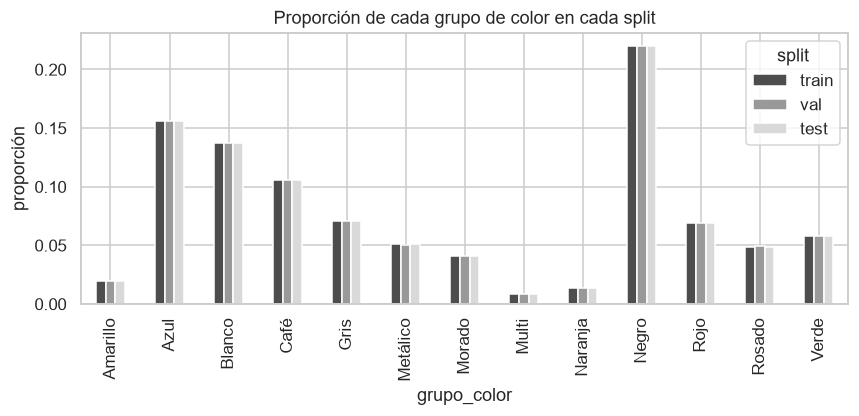

In [28]:
prop = pd.crosstab(d["grupo_color"], d["split"], normalize="columns")[["train", "val", "test"]]
prop.plot.bar(figsize=(9, 3.2), color=["0.3", "0.6", "0.85"])
plt.title("Proporción de cada grupo de color en cada split"); plt.ylabel("proporción")
guardar("09_balance_splits"); plt.show()

## 10. Revisión de anotaciones
* **Tipo de anotación:** una etiqueta de tono por producto (*single-label*). No hay cajas ni máscaras, así que la máscara del producto se obtiene aquí por umbral en CIELAB y más adelante con segmentación.
* **Jerarquía:** tono fino (46) → grupo básico (13). Se verificó que cada tono pertenece a un solo grupo.
* **Clase `Multi`:** no es un tono. Se propone excluirla del entrenamiento del tono principal o tratarla aparte.
* **Ambigüedad del objeto:** la etiqueta describe el **producto**, pero la foto puede incluir la persona, otras prendas y accesorios (ver sección 6).

In [29]:
assert d.groupby("baseColour")["grupo_color"].nunique().max() == 1
# Tonos metálicos: ¿están concentrados en pocos tipos de artículo?
print(d[d["grupo_color"] == "Metálico"]["articleType"].value_counts().head(8).to_string())

articleType
Watches         497
Earrings        324
Heels           230
Sunglasses      179
Pendant         158
Ring            114
Sports Shoes     78
Flats            72


## 11. Métricas exploratorias
**Separabilidad perceptual entre tonos.** Distancia CIEDE2000 entre los colores medianos de cada clase. Los pares con ΔE pequeño son los que más se van a confundir.

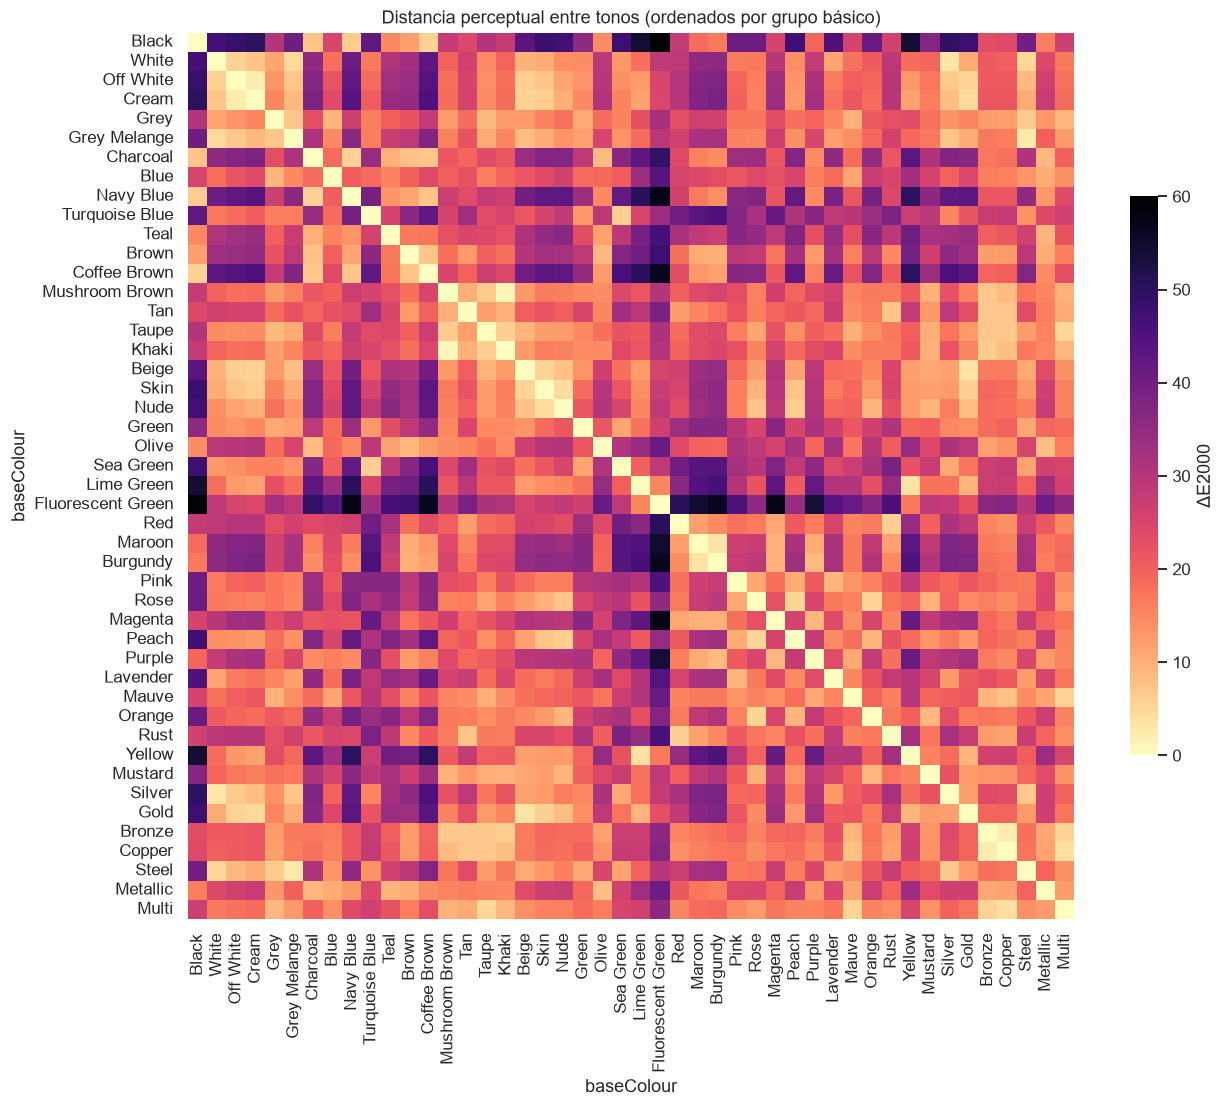

Pares de tonos más cercanos (ΔE2000):
baseColour      baseColour  
Mushroom Brown  Khaki           0.8
Off White       Cream           2.1
Bronze          Copper          2.3
Grey Melange    Steel           2.8
White           Silver          3.2
Maroon          Burgundy        3.3
Beige           Gold            3.4
Lime Green      Yellow          3.7
Copper          Multi           3.9
Skin            Nude            4.2
White           Grey Melange    4.5
Cream           Gold            4.5
Taupe           Multi           5.0
White           Steel           5.0
Beige           Skin            5.2


In [30]:
orden_grupos = [t for g in config.GRUPOS_COLOR for t in config.GRUPOS_COLOR[g] if t in centroides.index]
de = matriz_delta_e(centroides.loc[orden_grupos])
fig, ax = plt.subplots(figsize=(13, 11))
sns.heatmap(de, cmap="magma_r", vmax=60, square=True, cbar_kws={"label": "ΔE2000", "shrink": 0.6}, ax=ax)
ax.set_title("Distancia perceptual entre tonos (ordenados por grupo básico)")
guardar("11_matriz_delta_e"); plt.show()

pares = de.where(np.triu(np.ones(de.shape, bool), 1)).stack().sort_values()
print("Pares de tonos más cercanos (ΔE2000):")
print(pares.head(15).round(1).to_string())

In [31]:
# Variabilidad intra-clase: ΔE de cada producto al centroide de su tono, comparado con la distancia al tono vecino más cercano
from skimage import color as skcolor
intra = skcolor.deltaE_ciede2000(d[["L", "a", "b"]].values, centroides.loc[d["baseColour"], ["L", "a", "b"]].values)
d["dE_centroide"] = intra
vecino = de.replace(0, np.nan).min(axis=1)
resumen = pd.DataFrame({"dE_intra_mediana": d.groupby("baseColour")["dE_centroide"].median(),
                        "dE_tono_mas_cercano": vecino, "n": conteo}).sort_values("dE_tono_mas_cercano")
resumen["separable"] = resumen["dE_tono_mas_cercano"] > resumen["dE_intra_mediana"]
display(resumen.round(1).head(15))
print(f"Tonos cuya variabilidad interna supera la distancia al tono vecino: {(~resumen['separable']).sum()} de {len(resumen)}")

,dE_intra_mediana,dE_tono_mas_cercano,n,separable
baseColour,,,,
Khaki,10.8,0.8,139,False
Mushroom Brown,7.5,0.8,16,False
Off White,6.9,2.1,182,False
Cream,7.6,2.1,383,False
Bronze,12.9,2.3,89,False
Copper,11.6,2.3,83,False
Grey Melange,7.1,2.8,146,False
Steel,9.5,2.8,315,False
Silver,8.2,3.2,1089,False


Tonos cuya variabilidad interna supera la distancia al tono vecino: 45 de 46


In [32]:
# Línea base exploratoria (no es el modelo final): k-NN sobre el color mediano Lab + croma del producto
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, f1_score, top_k_accuracy_score

X = d[["L", "a", "b", "croma", "L_std", "croma_std"]].values
base = d["grupo_color"] != "Multi"
resultados = []
for objetivo in ["baseColour", "grupo_color"]:
    tr_m, te_m = base & (d["split"] == "train"), base & (d["split"] == "test")
    knn = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=25, weights="distance"))
    knn.fit(X[tr_m], d.loc[tr_m, objetivo])
    pred = knn.predict(X[te_m]); proba = knn.predict_proba(X[te_m])
    resultados.append({"objetivo": objetivo, "clases": d.loc[tr_m, objetivo].nunique(),
                       "accuracy": accuracy_score(d.loc[te_m, objetivo], pred),
                       "f1_macro": f1_score(d.loc[te_m, objetivo], pred, average="macro"),
                       "top3": top_k_accuracy_score(d.loc[te_m, objetivo], proba, k=3, labels=knn.classes_)})
    if objetivo == "grupo_color":
        pred_g, real_g = pred, d.loc[te_m, objetivo].values
pd.DataFrame(resultados).round(3)

,objetivo,clases,accuracy,f1_macro,top3
0,baseColour,45,0.572,0.201,0.799
1,grupo_color,12,0.638,0.577,0.871


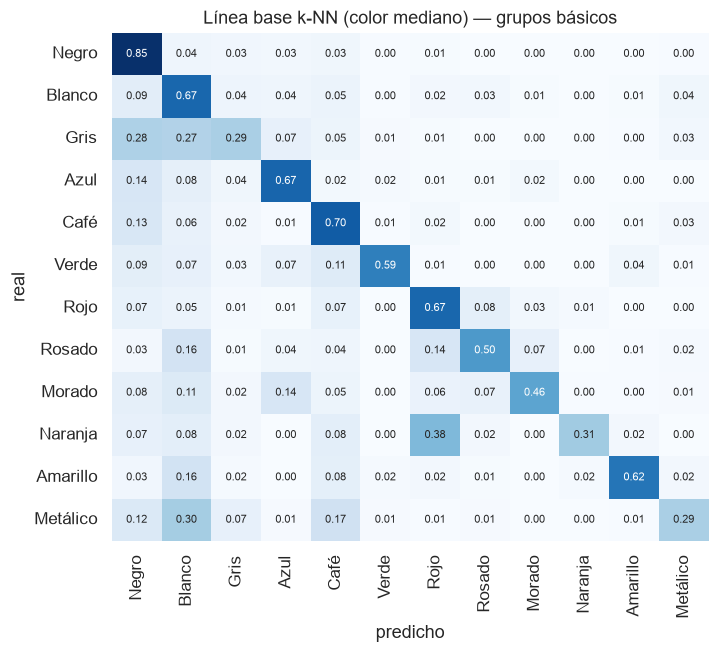

In [33]:
from sklearn.metrics import confusion_matrix
etiquetas = [g for g in config.GRUPOS_COLOR if g != "Multi"]
cm = confusion_matrix(real_g, pred_g, labels=etiquetas, normalize="true")
fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(cm, annot=True, fmt=".2f", cmap="Blues", xticklabels=etiquetas, yticklabels=etiquetas,
            annot_kws={"size": 7}, cbar=False, ax=ax)
ax.set(xlabel="predicho", ylabel="real", title="Línea base k-NN (color mediano) — grupos básicos")
guardar("11_confusion_baseline"); plt.show()

## 12. Documentación: hallazgos, riesgos y plan

In [34]:
hallazgos = {
    "Imágenes": f"{len(d):,}",
    "Tonos / grupos": f"{d['baseColour'].nunique()} / {d['grupo_color'].nunique()}",
    "Resolución": f"60x80 ({((d['ancho'] == 60) & (d['alto'] == 80)).mean():.1%})",
    "Desbalance mayor/menor": f"{conteo.max() / conteo.min():,.0f}x",
    "Clases < 100 imágenes": int((conteo < 100).sum()),
    "Imágenes corruptas": int(d["error"].notna().sum()),
    "Imágenes en gris (modo L)": int((d["modo"] == "L").sum()),
    "Duplicados exactos (imágenes)": f"{len(dup_exactos):,}",
    "Imagen idéntica con tonos distintos (grupos)": n_conf_md5,
    "Casi-duplicados dHash (imágenes)": f"{len(dup_percep):,}",
    "Acuerdo etiqueta vs nombre (fino / grupo)": f"{acuerdo_fino:.1%} / {acuerdo_grupo:.1%}",
    "Apparel con piel visible (heurística)": f"{(d.loc[d['masterCategory'] == 'Apparel', 'frac_piel'] > 0.10).mean():.0%}",
    "Baseline k-NN accuracy (46 / 13)": f"{resultados[0]['accuracy']:.0%} / {resultados[1]['accuracy']:.0%}",
}
pd.Series(hallazgos, name="valor").to_frame()

,valor
Imágenes,"44,072"
Tonos / grupos,46 / 13
Resolución,60x80 (99.9%)
Desbalance mayor/menor,"1,940x"
Clases < 100 imágenes,16
Imágenes corruptas,0
Imágenes en gris (modo L),430
Duplicados exactos (imágenes),"1,429"
Imagen idéntica con tonos distintos (grupos),52
Casi-duplicados dHash (imágenes),"2,046"


### Síntesis de hallazgos
1. **Desbalance extremo de cola larga.** Black tiene 9.699 imágenes y Lime Green y Fluorescent Green tienen 5 cada una (≈1.940x). Las 5 clases más grandes concentran el 60 % de los datos y 16 tonos tienen menos de 100 imágenes.
2. **Los tonos finos se solapan perceptualmente.** Hay pares con ΔE2000 menor a 4 entre sus colores medianos (Khaki/Mushroom Brown, Off White/Cream, Bronze/Copper, Maroon/Burgundy, Skin/Nude). En 45 de 46 tonos la dispersión interna supera la distancia al tono vecino. La taxonomía de 46 clases es ambigua incluso para humanos, y eso justifica la salida jerárquica (46 → 13).
3. **Las etiquetas son buenas pero tienen ruido.** El acuerdo con el nombre comercial es ≈94 % (tono fino), y hay imágenes idénticas publicadas con tonos distintos. Los desacuerdos se concentran en productos con dos colores (p. ej. Black/Red) y en tonos vecinos (Navy Blue/Blue).
4. **El producto no es toda la foto.** El 98 % de las imágenes tiene fondo blanco (el 67 % de los píxeles es casi blanco). En las prendas suele aparecer el modelo (piel, cabello, otras prendas), lo que contamina el color medido. La segmentación del producto es necesaria.
5. **Sesgo tono–categoría.** Los tonos metálicos (Silver, Gold, Steel, Bronze, Copper) están casi solo en relojes y joyería, y Grey Melange solo en ropa. Existe el riesgo de que el modelo aprenda el tipo de producto en vez del color.
6. **Calidad técnica alta.** No hay imágenes corruptas. El 99,9 % de las imágenes es de 60x80, 430 están en escala de grises (casi todas Black, White o Silver, coherente) y ~1 % es borroso.
7. **El color mediano solo no alcanza.** Un k-NN sobre el color Lab del primer plano logra 57 % de accuracy y F1-macro 0,20 en 46 tonos, y 64 % en 13 grupos. Esa es la línea base a superar.

### Riesgos para el modelado
* Las clases minoritarias quedan con 1 a 3 ejemplos en validación y prueba (Lime Green, Fluorescent Green, Taupe), así que sus métricas serán muy ruidosas.
* La resolución de 60x80 limita la textura. La versión de Kaggle en alta resolución (~25 GB) es la alternativa si hace falta.
* El aumento de datos fotométrico invalida la etiqueta (sección 8).
* La clase `Multi` no es un tono.

## Estrategia propuesta para el modelado

| Aspecto | Propuesta |
|---|---|
| **Tarea** | Clasificación multiclase de tono (46) con cabeza jerárquica de grupo básico (13). `Multi` se excluye o se trata como clase aparte. |
| **Preparación** | Segmentación del producto. Línea base: máscara por ΔE contra el fondo (este EDA). Mejora: SAM o un segmentador de prendas para quitar piel y fondo. Redimensionar a 224 con *padding* blanco y normalizar con la media y desviación del dataset (≠ ImageNet). |
| **Modelos** | (1) **Clásico**: descriptores CIELAB (histograma a\*b\* del primer plano, color dominante por k-means) + SVM/k-NN. (2) **Transfer learning**: ResNet-50 / ConvNeXt-T / ViT-B preentrenados, primero *fine-tuning* de la cabeza y luego de todo el modelo. (3) **Fundacional zero-shot**: CLIP con prompts "a photo of a {tono} product". (4) Opcional: destilación de conocimiento hacia un modelo liviano para la herramienta del área comercial. |
| **Función de costo** | Cross-entropy ponderada por frecuencia o *focal loss* (desbalance) + *label smoothing* guiado por ΔE (confundir tonos vecinos penaliza menos) + pérdida auxiliar del grupo básico. |
| **Aumento de datos** | Solo geométrico: flip, rotación ±15°, recorte y escala, traslación. **Sin** ColorJitter de tono o saturación. Para las clases raras: *oversampling* y, si hace falta, *mixup* solo entre imágenes del mismo tono. |
| **Datos adicionales** | Si las clases raras no alcanzan: imágenes de alta resolución de Kaggle, o fusionar las clases con < 30 ejemplos en su vecino perceptual. |
| **Evaluación** | Split 70/15/15 estratificado y agrupado por casi-duplicados (sección 9). Métricas: accuracy y F1-macro (46 y 13), top-3, **ΔE2000 medio del error** y matriz de confusión. Grad-CAM para verificar que el modelo mira el producto y no el fondo ni la categoría. |
| **Entorno** | Google Colab (GPU T4) o GPU local, PyTorch + torchvision / timm / open_clip. Registro de experimentos con semilla fija. |
| **Despliegue (opcional)** | Herramienta para el área comercial: recibe la foto del requerimiento, segmenta la prenda, predice el tono (top-3) y su color Lab, y lo compara por ΔE2000 contra el catálogo de colorantes (requiere las coordenadas Lab de cada referencia, aportadas por la empresa). |